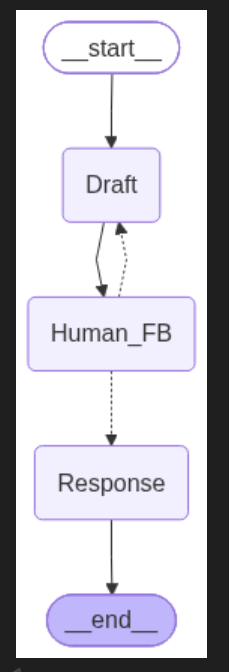

In [1]:
from dotenv import load_dotenv
load_dotenv()

True

In [2]:
from langgraph.graph import StateGraph, START, END
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import InMemorySaver
from langchain_anthropic import ChatAnthropic
from pydantic import BaseModel
from typing import Literal

In [3]:
# STEPS
# State -> Nodes ->

In [4]:
# State to store data
class MailState(BaseModel):
    query: str = ""
    draft:str = ""
    human_feedback: str = ""
    final_response: str = ""

In [5]:
llm = ChatAnthropic(model="claude-sonnet-5-5")
memory = InMemorySaver()

In [ ]:
# Nodes

# this node is responsible for:
# - based on the user question
# - create/store the informations in the draft
def DraftEmail(state:MailState) -> MailState:
    # if there is "Human Feedback". Go to "IF" block, otherwise Go to "else" block 
    if state.human_feedback:
        draft = llm.invoke(
            f'''
            Update the draft based on {state.query},
            You have already generated a draft {state.draft},
            human asked to update {state.human_feedback}
            '''
        ).content
    else:
        draft = llm.invoke(state.query).content
    state.draft = draft
    return state

# this node will determine, either we have to continue, or return to the draft for update the info.
# for human intract, we use "interrucpt" method
def HumanFeedback(state:MailState) -> MailState:
    feedback = interrupt({
        "draft_email": state.draft, # tell the model about the current draft/email
        "question": "Do you want to continue or modify the email?"
    })

    fb = (feedback or "").strip().lower()
    if fb in ["approved", "ok", "yes"]:
        state.human_feedback = ""
        return state
    else:
        state.human_feedback = feedback
        return state

def FinalResponse(state:MailState) -> MailState:
    if state.human_feedback:
        # if human gave some feed back, add it to the final response.
        state.final_response = state.human_feedback
        return state
    else:
        # if human approved, we can return the draft as final response.
        print("Email has been sent.")
        state.final_response = "Email has been sent."
        return state

# Condational Node
# this node will decide either we have to go "draft" or "finalResponse"
def CondationalRouting(state:MailState) -> Literal["Draft", "Response"]:
    if state.human_feedback:
        # if human gave some feed back, we need to go back to the draft.
        return "Draft"
    else:
        # if human approved, we can go to the final response.
        return "Response"
    

In [8]:
graph_builder = StateGraph(MailState)

# nodes
graph_builder.add_node("Draft", DraftEmail)
graph_builder.add_node("Human_FB", HumanFeedback)
graph_builder.add_node("Response", FinalResponse)

# edges
graph_builder.add_edge(START, "Draft")
graph_builder.add_edge("Draft", "Human_FB")
graph_builder.add_conditional_edges("Human_FB", CondationalRouting)
graph_builder.add_edge("Response", END)

# compile graph
graph = graph_builder.compile(checkpointer=memory)
# graph

In [9]:
config = {"configurable":{"thread_id":"1"}}
res = graph.invoke(
    {"query": "Write an email to my professor, asking for a recommendation letter."},
    config=config
)


In [10]:
print(res["draft"])

Subject: Request for a Letter of Recommendation  

Dear Professor [Last Name],

I hope you are doing well. I am writing to ask if you would be willing to write a letter of recommendation for me as I apply to [program/scholarship/internship/job] at [institution/organization].  

I greatly enjoyed and benefited from your [course name, e.g., “Advanced Microeconomics”] during the [semester/year] and especially valued the project on [briefly mention a specific project or topic you worked on]. Your insight into my analytical abilities and work ethic would provide a strong endorsement for my application.

The deadline for the recommendation is **[date]**. If you are able to support me, I can provide the following to make the process easier:

- My current résumé/CV  
- A draft of my personal statement  
- A summary of the projects and assignments I completed in your class  
- Any specific forms or submission instructions required by the program  

Please let me know if you need any additional 

In [ ]:
# we use "command" method to give feedback to AI
# res2 = graph.invoke(Command(resume="I do not want to send this email."), config=config)
res2 = graph.invoke(Command(resume="Keep the email short."), 
                                    config=config)

In [ ]:
res2

In [ ]:
print(res2["draft"])

Subject: Request for a Recommendation Letter – Risk & Compliance Officer Position  

Dear Professor Lutya Ayman,

I hope you are doing well. I am writing to ask if you would be willing to provide a recommendation letter for me as I apply for the **Risk and Compliance Officer** position at [Company Name].

Having taken your courses in Risk Management and Corporate Governance, I greatly benefited from your insights into regulatory frameworks and internal controls. Your perspective on my analytical abilities, attention to detail, and commitment to ethical standards would be especially valuable to the hiring committee.

If you are able to support my application, the letter should be submitted by **[deadline date]** (the employer’s deadline). I can provide my résumé, the job description, and any additional information you might need to tailor the recommendation.

Thank you very much for considering my request. I truly appreciate your guidance and the time you would invest in helping me purs